# Error analysis

Understanding and reporting where the four models go wrong on the validation split. 

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

from src.data import load

plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"figures/{name}.png"); plt.show()

pd.set_option("display.precision", 3)

## 1. Load predictions

In [2]:
# run with the highest validation accuracy for each model
BEST = {
    "image": {"knn": "k100_cos_exp0.025_logtfidf", "tree": "dnone_ms2_ml10_gini_mf32_b256_pca50",
              "forest": "n200_dnone_mfsqrt_logtfidf", "nn": "h256_lr1e-3_do0.2_wd0_adam_gelu_bs256_standardise"},
    "sentiment": {"knn": "k100_exp2_pca200", "tree": "d4_ms2_ml1_gini_raw",
                  "forest": "n100_dnone_mf64_raw", "nn": "h256x64_lr1e-4_do0_wd0_adam_raw"},
}
SENT_NAMES = ["negative", "neutral", "positive"]

def pred_folder(dataset, model, run_id):
    root = Path("runs") if model == "nn" else Path("cache/preds")
    return root / dataset / model / run_id

y_val, proba, pred = {}, {}, {}
rows = []
for dataset, runs in BEST.items():
    y_val[dataset] = load(dataset, "raw")[3]
    proba[dataset], pred[dataset] = {}, {}
    for model, run_id in runs.items():
        folder = pred_folder(dataset, model, run_id)
        if not (folder / "val_proba.npy").exists():
            print(f"missing {folder}: run python -m experiments.preds first (skipped here)")
            continue
        proba[dataset][model] = np.load(folder / "val_proba.npy")
        pred[dataset][model] = proba[dataset][model].argmax(axis=1)
        logged = json.loads((Path("runs") / dataset / model / run_id / "config.json").read_text())["val_acc"]
        acc = (pred[dataset][model] == y_val[dataset]).mean()
        rows.append({"dataset": dataset, "model": model, "run_id": run_id, "val_acc": acc, "logged_val_acc": logged})
overall = pd.DataFrame(rows)
assert np.allclose(overall["val_acc"], overall["logged_val_acc"], atol=1e-3), "a prediction file does not match its run"
overall

,dataset,model,run_id,val_acc,logged_val_acc
0,image,knn,k100_cos_exp0.025_logtfidf,0.600,0.600
1,image,tree,dnone_ms2_ml10_gini_mf32_b256_pca50,0.132,0.132
2,image,forest,n200_dnone_mfsqrt_logtfidf,0.321,0.321
3,image,nn,h256_lr1e-3_do0.2_wd0_adam_gelu_bs256_standardise,0.343,0.343
4,sentiment,knn,k100_exp2_pca200,0.605,0.605
5,sentiment,tree,d4_ms2_ml1_gini_raw,0.503,0.503
6,sentiment,forest,n100_dnone_mf64_raw,0.602,0.602
7,sentiment,nn,h256x64_lr1e-4_do0_wd0_adam_raw,0.668,0.668


Every file matches its logged accuracy. k-NN is best on image at 0.600, the network on sentiment at 0.668.

## 2. Sentiment: scores per class

In [3]:
ys = y_val["sentiment"]
rows = []
for model, p in pred["sentiment"].items():
    prec, rec, f1, _ = precision_recall_fscore_support(ys, p, labels=[0, 1, 2], zero_division=0)
    share = np.bincount(p, minlength=3) / len(p)
    for c, name in enumerate(SENT_NAMES):
        rows.append({"model": model, "class": name, "precision": prec[c], "recall": rec[c], "f1": f1[c],
                     "predicted_share": share[c]})
sent_prf = pd.DataFrame(rows)
sent_prf.pivot(index="model", columns="class", values=["recall", "precision", "f1", "predicted_share"])

recall                  precision                        f1          \
class  negative neutral positive  negative neutral positive negative neutral   
model                                                                          
forest    0.695   0.489    0.621     0.613   0.532    0.656    0.651   0.509   
knn       0.756   0.370    0.690     0.591   0.635    0.606    0.664   0.468   
nn        0.725   0.578    0.701     0.710   0.591    0.700    0.717   0.584   
tree      0.651   0.295    0.564     0.515   0.448    0.524    0.575   0.356   

                predicted_share                   
class  positive        negative neutral positive  
model                                             
forest    0.638           0.378   0.306    0.316  
knn       0.645           0.426   0.194    0.380  
nn        0.701           0.340   0.326    0.334  
tree      0.543           0.422   0.220    0.359

Neutral is the lowest perfoming class for every model. k-NN predicts it for only 19% of rows and the network predicts it for 33%.

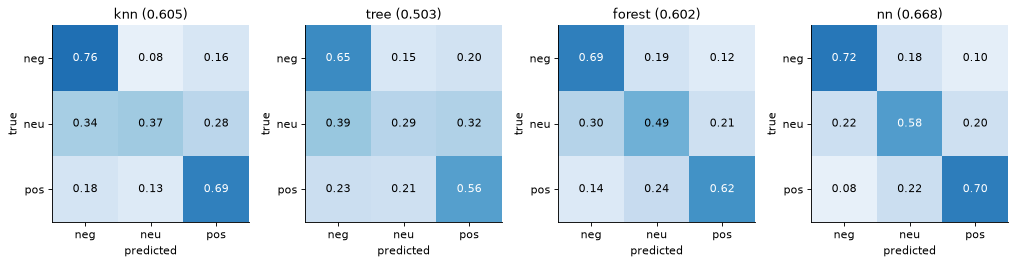

In [4]:
fig, axes = plt.subplots(1, len(pred["sentiment"]), figsize=(3.2 * len(pred["sentiment"]), 3.2))
for ax, (model, p) in zip(np.atleast_1d(axes), pred["sentiment"].items()):
    cm = confusion_matrix(ys, p, labels=[0, 1, 2], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), ["neg", "neu", "pos"]); ax.set_yticks(range(3), ["neg", "neu", "pos"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{model} ({(p == ys).mean():.3f})")
save(fig, "sentiment_confusion")

In [5]:
# split errors into those that involve neutral, as true or predicted label, and negative-positive swaps
rows = []
for model, p in pred["sentiment"].items():
    wrong = p != ys
    neutral = wrong & ((ys == 1) | (p == 1))
    rows.append({"model": model, "errors": int(wrong.sum()), "share_involving_neutral": neutral.sum() / wrong.sum(),
                 "share_neg_pos_swap": (wrong & ~neutral).sum() / wrong.sum()})
pd.DataFrame(rows)

,model,errors,share_involving_neutral,share_neg_pos_swap
0,knn,947,0.712,0.288
1,tree,1192,0.717,0.283
2,forest,956,0.788,0.212
3,nn,797,0.826,0.174


83% of the network's errors involve neutral and only 17% mix up negative and positive.  Since Neutral is  between the two it gets confused with both.

The sentiment test set is shifted from train, and a simple classifier predicts 47% negative on test against 36% on validation. So the class mix on test differs, and the errors here may not match test errors.

![Sentiment train/test shift per feature and on the top two principal components](../figures/eda_sentiment_shift.png)

## 3. Image: per-class accuracy and confused pairs

In [6]:
yi = y_val["image"]
per_class = pd.DataFrame({model: [(p[yi == c] == c).mean() for c in range(50)] for model, p in pred["image"].items()})
per_class.index.name = "class"
print("per-class accuracy, spread over the 50 classes:")
display(per_class.describe().loc[["mean", "min", "25%", "50%", "75%", "max"]])
order = per_class["knn"].sort_values().index
print("hardest and easiest classes for k-NN:")
pd.concat([per_class.loc[order[:8]], per_class.loc[order[-5:]]])

per-class accuracy, spread over the 50 classes:


,knn,tree,forest,nn
mean,0.600,0.132,0.321,0.343
min,0.412,0.000,0.075,0.087
25%,0.525,0.062,0.200,0.237
50%,0.588,0.094,0.275,0.300
75%,0.662,0.163,0.422,0.459
max,0.938,0.625,0.800,0.787


hardest and easiest classes for k-NN:


,knn,tree,forest,nn
class,,,,
29,0.412,0.050,0.087,0.087
9,0.438,0.062,0.087,0.150
10,0.450,0.087,0.237,0.200
41,0.475,0.062,0.200,0.150
6,0.475,0.138,0.150,0.237
22,0.475,0.062,0.075,0.087
42,0.475,0.025,0.200,0.237
23,0.500,0.075,0.200,0.300
12,0.775,0.175,0.537,0.463


k-NN's accuracy per class runs from 0.41 to 0.94 and the other models are worse on nearly every class.

In [7]:
def confused_pairs(y, p, top=12):
    cm = confusion_matrix(y, p, labels=range(50))
    sym = cm + cm.T                      # i->j and j->i together
    rows = [{"pair": f"{i}-{j}", "count": int(sym[i, j]), "i_as_j": int(cm[i, j]), "j_as_i": int(cm[j, i]),
             "neighbouring_ids": j - i == 1}
            for i in range(50) for j in range(i + 1, 50)]
    return pd.DataFrame(rows).sort_values("count", ascending=False).head(top).reset_index(drop=True)

print("k-NN, most confused class pairs (80 validation rows per class):")
confused_pairs(yi, pred["image"]["knn"])

k-NN, most confused class pairs (80 validation rows per class):


,pair,count,i_as_j,j_as_i,neighbouring_ids
0,37-38,15,7,8,True
1,2-3,13,3,10,True
2,12-13,12,4,8,True
3,38-39,11,2,9,True
4,2-4,10,2,8,False
5,25-27,10,0,10,False
6,6-7,9,7,2,True
7,1-2,8,5,3,True
8,5-6,8,2,6,True
9,46-47,7,0,7,True


8 of the 12 most confused pairs are adjacent label ids, lik
 37 and 38.

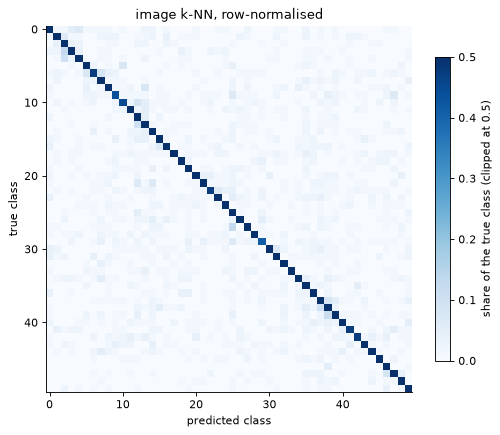

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cm = confusion_matrix(yi, pred["image"]["knn"], labels=range(50), normalize="true")
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=0.5)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title("image k-NN, row-normalised")
fig.colorbar(im, ax=ax, shrink=0.8, label="share of the true class (clipped at 0.5)")
save(fig, "image_knn_confusion")

## 4. Do the models make the same mistakes?

In [9]:
# one table per dataset: True where a model labels a validation row correctly
correct = {d: pd.DataFrame({m: p == y_val[d] for m, p in pred[d].items()}) for d in BEST}

for dataset, ok in correct.items():
    wrong = ~ok
    # of the row model's errors, the share the column model also gets wrong
    both_wrong = pd.DataFrame({b: [(wrong[a] & wrong[b]).sum() / wrong[a].sum() for a in ok] for b in ok},
                              index=ok.columns)
    summary = pd.Series({"best single model right": ok.mean().max(),
                         "at least one model right": ok.any(axis=1).mean(),
                         "all models right": ok.all(axis=1).mean(),
                         "all models wrong": wrong.all(axis=1).mean()})
    print(f"--- {dataset}: of the row model's errors, share the column model also gets wrong")
    display(both_wrong)
    display(summary.to_frame("share of validation rows"))

--- image: of the row model's errors, share the column model also gets wrong


,knn,tree,forest,nn
knn,1.000,0.944,0.887,0.845
tree,0.435,1.000,0.730,0.709
forest,0.523,0.933,1.000,0.799
nn,0.514,0.936,0.825,1.000


,share of validation rows
best single model right,0.600
at least one model right,0.702
all models right,0.071
all models wrong,0.298


--- sentiment: of the row model's errors, share the column model also gets wrong


,knn,tree,forest,nn
knn,1.000,0.687,0.736,0.587
tree,0.546,1.000,0.556,0.454
forest,0.729,0.694,1.000,0.610
nn,0.698,0.679,0.731,1.000


,share of validation rows
best single model right,0.668
at least one model right,0.849
all models right,0.309
all models wrong,0.151


On image, mostly yes: the network also gets 85% of k-NN's errors wrong. On sentiment, less so: at least one model is right on 85% of rows, while the best one alone gets 67%.

In [10]:
# of one model's wrong rows, the share the other model gets right
rows = []
for dataset, ok in correct.items():
    for m in [m for m in ok if m != "nn"]:
        rows.append({"dataset": dataset, "model": m,
                     "nn fixes model's errors": (~ok[m] & ok["nn"]).sum() / (~ok[m]).sum(),
                     "model fixes nn's errors": (ok[m] & ~ok["nn"]).sum() / (~ok["nn"]).sum()})
pd.DataFrame(rows)

,dataset,model,nn fixes model's errors,model fixes nn's errors
0,image,knn,0.155,0.486
1,image,tree,0.291,0.064
2,image,forest,0.201,0.175
3,sentiment,knn,0.413,0.302
4,sentiment,tree,0.546,0.321
5,sentiment,forest,0.390,0.269


The network fixes 16% of k-NN's image errors and 41% of its sentiment errors. Averaging the sentiment models still did not beat the network alone.

In [11]:
# Best model on the hard classes: the 10 classes with the lowest mean accuracy over the models
hard = per_class.mean(axis=1).sort_values().index[:10]
tab = per_class.loc[hard].copy()
tab["best model"] = tab.idxmax(axis=1)
print("image, 10 hardest classes:")
display(tab)
print("sentiment, recall on the hardest class (neutral):")
sent_prf[sent_prf["class"] == "neutral"].set_index("model")[["recall", "precision", "f1"]]

image, 10 hardest classes:


,knn,tree,forest,nn,best model
class,,,,,
29,0.412,0.050,0.087,0.087,knn
22,0.475,0.062,0.075,0.087,knn
9,0.438,0.062,0.087,0.150,knn
21,0.537,0.000,0.113,0.188,knn
41,0.475,0.062,0.200,0.150,knn
42,0.475,0.025,0.200,0.237,knn
40,0.500,0.050,0.188,0.212,knn
10,0.450,0.087,0.237,0.200,knn
1,0.525,0.075,0.188,0.188,knn


sentiment, recall on the hardest class (neutral):


,recall,precision,f1
model,,,
knn,0.370,0.635,0.468
tree,0.295,0.448,0.356
forest,0.489,0.532,0.509
nn,0.578,0.591,0.584


k-NN is the best model on all 10 of the hardest image classes.

## 5. Normalisation, tree depth and the forest

In [12]:
res = pd.read_csv("results/results.csv")
print("Best validation accuracy per transform:")
res[res.model == "knn"].groupby(["dataset", "transform"]).val_acc.max().unstack(0)

Best validation accuracy per transform:


dataset,image,sentiment
transform,,
logtfidf,0.600,NaN
pca100,NaN,0.591
pca200,NaN,0.605
pca50,NaN,0.589
raw,0.531,0.591
standardise,0.534,0.589


Normalisation helps k-NN on image: log-tfidf gets 0.600 against 0.531 raw, and standardising only 0.534, so the gain comes from reweighting the word counts. The EDA showed image rows are normalised word counts, which is what makes that reweighting possible. On sentiment every transform lands between 0.589 and 0.605, even though the EDA found feature 308 dominates raw distances.

![Recovered word counts per entry and words per image](../figures/eda_image_counts.png)

,dataset,max_depth,train_acc,val_acc
0,image,1.0,0.029,0.029
1,image,3.0,0.045,0.044
2,image,5.0,0.060,0.058
3,image,10.0,0.102,0.069
4,image,20.0,0.242,0.101
5,image,NaN,1.000,0.113


,dataset,max_depth,train_acc,val_acc
0,sentiment,1.0,0.431,0.428
1,sentiment,3.0,0.469,0.457
11,sentiment,4.0,0.513,0.503
2,sentiment,5.0,0.530,0.502
14,sentiment,6.0,0.572,0.483
17,sentiment,7.0,0.614,0.474
20,sentiment,8.0,0.679,0.475
3,sentiment,10.0,0.821,0.470
4,sentiment,20.0,0.998,0.445
5,sentiment,NaN,1.000,0.444


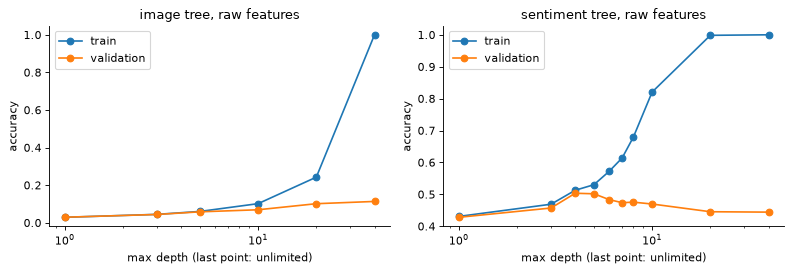

In [13]:
curve = pd.read_csv("results/tree_curve_image.csv"), pd.read_csv("results/tree_curve_sentiment.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, c in zip(axes, curve):
    # keep only the plain depth sweep: raw features, all features, no other limit. The files also hold later sweeps.
    keep = (c.min_samples_split == 2) & (c.min_samples_leaf == 1) & (c.criterion == "gini") & (c.n_bins == 64)
    if "transform" in c:
        keep &= (c["transform"] == "raw") & c.max_features.isna()
    c = c[keep].drop_duplicates("max_depth").copy()
    c["depth"] = c.max_depth.fillna(c.max_depth.max() * 2)      # unlimited depth plotted at the right
    c = c.sort_values("depth")
    ax.plot(c.depth, c.train_acc, marker="o", label="train"); ax.plot(c.depth, c.val_acc, marker="o", label="validation")
    ax.set_xscale("log"); ax.set_xlabel("max depth (last point: unlimited)"); ax.set_ylabel("accuracy")
    ax.set_title(f"{c.dataset.iloc[0]} tree, raw features"); ax.legend()
    display(c[["dataset", "max_depth", "train_acc", "val_acc"]])
save(fig, "tree_depth")

Sentiment trees overfit past depth 4: training accuracy reaches 1.000 while validation falls from 0.503 to 0.444. Image trees never pass 0.113 on validation and one of the trees cannot separate 50 classes.

In [14]:
# Compare validation accuracy at unlimited depth as trees are added.
rows = []
for dataset in BEST:
    tc = pd.read_csv(f"results/tree_curve_{dataset}.csv")
    single = tc[tc.max_depth.isna() & (tc.min_samples_split == 2) & (tc.min_samples_leaf == 1) & (tc.n_bins == 64)
                & ((tc["transform"] == "raw") & tc.max_features.isna() if "transform" in tc else True)].iloc[0]
    rows.append({"dataset": dataset, "n_trees": 1, "train_acc": single.train_acc, "val_acc": single.val_acc})
    fc = pd.read_csv(f"results/forest_tree_comparison_{dataset}.csv")
    fc = fc[(fc.model == "forest") & fc.max_depth.isna()]
    for n, g in fc.groupby("n_trees"):
        top = g.loc[g.val_acc.idxmax()]
        rows.append({"dataset": dataset, "n_trees": n, "train_acc": top.train_acc, "val_acc": top.val_acc})
pd.DataFrame(rows).pivot(index="n_trees", columns="dataset", values=["train_acc", "val_acc"])

train_acc           val_acc          
dataset     image sentiment   image sentiment
n_trees                                      
1           1.000      1.00   0.113     0.444
10          0.998      0.99   0.150     0.511
50          1.000      1.00   0.242     0.580
100         1.000      1.00   0.285     0.602
200         1.000       NaN   0.321       NaN

Each forest tree still fits the training rows, but averaging them lifts validation from 0.113 to 0.321 on image and from 0.444 to 0.602 on sentiment. The trees see different rows and features so their errors partly cancel.